# B4: Konvolusi dan Penapisan Spasial
SIMUTEH | SEED = 1013 | NIM 2330511013

In [1]:
import sys, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
D = "../data/sintetis"

## Langkah 4.2 Verifikasi konvolusi manual (Kode 4.1)

In [2]:
def konvolusi(img, k):            # fungsi dari slide P4 (sebenarnya KORELASI)
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"{D}/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"{D}/mask_daun/{nama}", 0)
mb = cv2.imread(f"{D}/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
              }.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c_ = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c_.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.070 s, filter2D=0.00038 s


asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.078 s, filter2D=0.00026 s


## Langkah 4.3 Tiga penapis, dua jenis derau (Kode 4.2)

In [3]:
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):             # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):   # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel.to_string(index=False))
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

   derau  penapis  PSNR_dB  waktu_ms   KB
gauss_10    tanpa    28.11      0.00 3.55
gauss_10 rerata_3    36.80      0.06 5.54
gauss_10 rerata_5    37.31      0.07 5.59
gauss_10  gauss_5    37.58      0.16 5.67
gauss_10 median_3    35.47      0.07 5.55
gauss_10 median_5    38.29      0.55 6.32
gauss_10 median_9    38.24     10.23 6.95
gauss_20    tanpa    22.13      0.00 2.01
gauss_20 rerata_3    31.42      0.06 4.43
gauss_20 rerata_5    34.34      0.07 5.09
gauss_20  gauss_5    32.55      0.20 4.72
gauss_20 median_3    29.73      0.07 4.03
gauss_20 median_5    33.40      0.56 5.16
gauss_20 median_9    35.29     12.15 5.77
gauss_40    tanpa    16.64      0.00 1.06
gauss_40 rerata_3    26.03      0.06 2.88
gauss_40 rerata_5    29.81      0.07 3.95
gauss_40  gauss_5    27.22      0.17 3.21
gauss_40 median_3    23.83      0.07 2.46
gauss_40 median_5    27.81      0.86 3.50
gauss_40 median_9    31.20     11.36 4.25
   sp_4%    tanpa    18.95      0.00 1.53
   sp_4% rerata_3    28.07      0.

 penapis  PSNR_dB_g20  waktu_ms_g20  KB_g20  PSNR_dB_sp4  waktu_ms_sp4  KB_sp4
   tanpa        22.13          0.00    2.01        18.95          0.00    1.53
rerata_3        31.42          0.06    4.43        28.07          0.06    3.78
rerata_5        34.34          0.07    5.09        31.24          0.07    4.72
 gauss_5        32.55          0.20    4.72        29.16          0.17    4.12
median_3        29.73          0.07    4.03        47.63          0.07    6.41
median_5        33.40          0.56    5.16        44.48          0.56    6.52
median_9        35.29         12.15    5.77        40.34         12.72    6.80


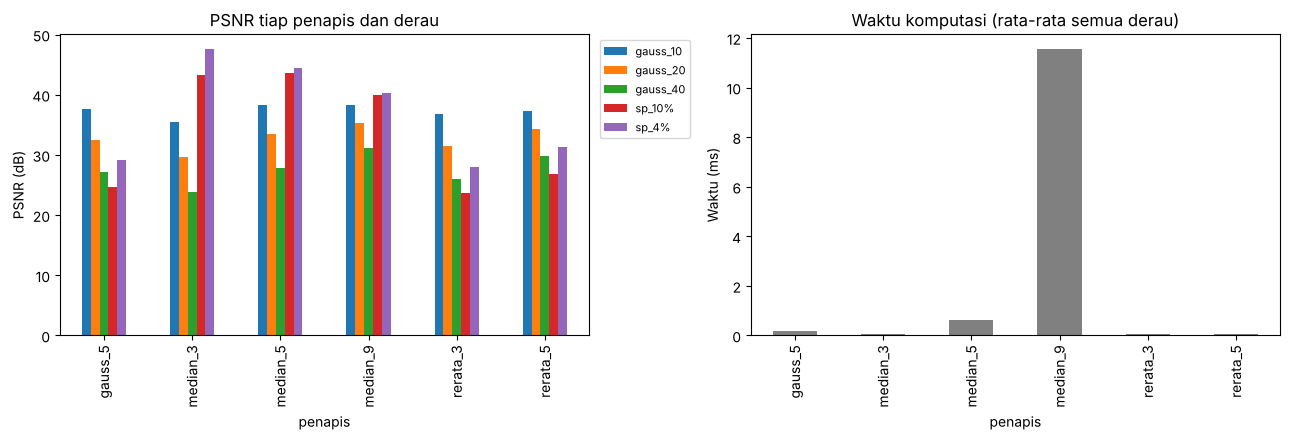

In [4]:
# Tabel 11: Gaussian 20 dan garam-merica 4%
t11 = tabel[tabel.derau == "gauss_20"].merge(tabel[tabel.derau == "sp_4%"], on="penapis", suffixes=("_g20", "_sp4"))
t11 = t11[["penapis", "PSNR_dB_g20", "waktu_ms_g20", "KB_g20", "PSNR_dB_sp4", "waktu_ms_sp4", "KB_sp4"]]
print(t11.to_string(index=False)); t11.to_csv("../hasil/b4_tabel11.csv", index=False)

# grafik PSNR dan waktu untuk seluruh hasil
p = tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau", values="PSNR_dB")
w = tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau", values="waktu_ms").mean(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
p.plot(kind="bar", ax=ax[0]); ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR tiap penapis dan derau"); ax[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
w.plot(kind="bar", ax=ax[1], color="gray"); ax[1].set_ylabel("Waktu (ms)"); ax[1].set_title("Waktu komputasi (rata-rata semua derau)")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr_waktu.png")

## Langkah 4.4 Apakah bercak kecil tetap terjaga? (Kode 4.3)

In [5]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv(f"{D}/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"{D}/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"{D}/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"{D}/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:          # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata_median = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rata_median)
rata_median.to_csv("../hasil/b4_median_kernel.csv")

           dI    KB
kernel             
1       27.70  4.43
3       28.25  4.58
5       27.19  4.49
9       21.37  4.12
15       7.23  2.01


luas bercak terkecil (piksel): 135 | diameter ekuivalen ~ 13.1


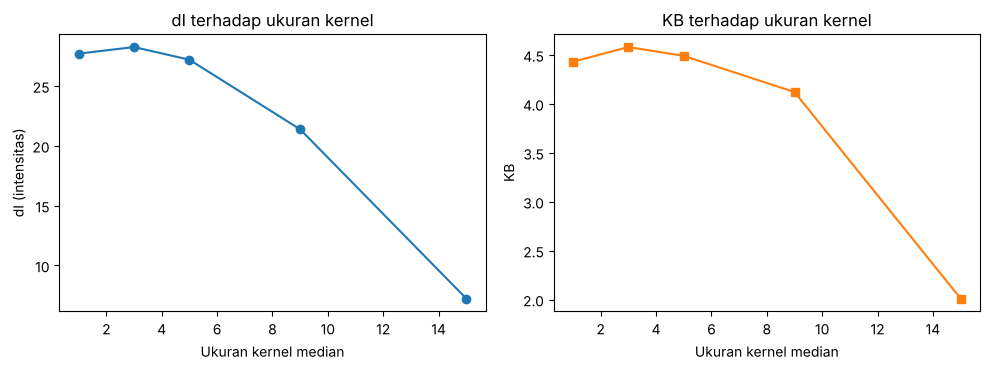

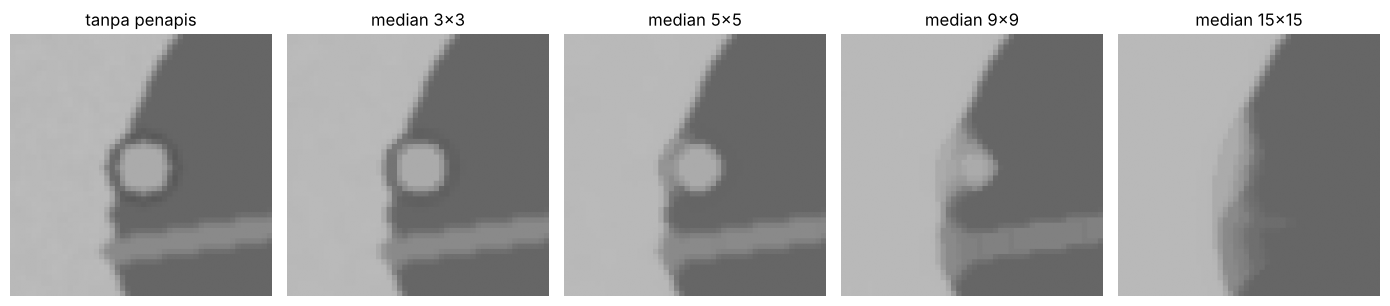

In [6]:
# grafik dI dan KB terhadap ukuran kernel
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(rata_median.index, rata_median.dI, "o-"); ax[0].set_xlabel("Ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)"); ax[0].set_title("dI terhadap ukuran kernel")
ax[1].plot(rata_median.index, rata_median.KB, "s-", color="C1"); ax[1].set_xlabel("Ukuran kernel median"); ax[1].set_ylabel("KB"); ax[1].set_title("KB terhadap ukuran kernel")
plt.tight_layout(); plt.savefig("../hasil/b4_dI_kernel.png")

# crop satu bercak kecil yang diperbesar (bercak terkecil pada teh_021)
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"{D}/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"{D}/mask_bercak/{nm}", 0)
n, lab, stat, cen = cv2.connectedComponentsWithStats((mb2 > 0).astype(np.uint8))
i = 1 + np.argmin(stat[1:, cv2.CC_STAT_AREA])
cx, cy = map(int, cen[i]); r = 25
fig, ax = plt.subplots(1, 5, figsize=(14, 3.2))
for a, k in zip(ax, [1, 3, 5, 9, 15]):
    out = g if k == 1 else cv2.medianBlur(g, k)
    a.imshow(cv2.resize(out[cy-r:cy+r, cx-r:cx+r], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST), cmap="gray", vmin=0, vmax=255)
    a.set_title("tanpa penapis" if k == 1 else f"median {k}x{k}"); a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b4_crop_bercak.png")
print("luas bercak terkecil (piksel):", stat[i, cv2.CC_STAT_AREA], "| diameter ekuivalen ~", round(2*np.sqrt(stat[i, cv2.CC_STAT_AREA]/np.pi), 1))

## Langkah 4.5 Urutan meredam derau dan menajamkan (Kode 4.4)

In [7]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0                       # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))         # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))         # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} sigma_latar={A[latar].std():.1f} | "
          f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.41 sigma_latar=7.9 | redam->tajam PSNR=30.21 sigma_latar=8.3


Median: tajam->redam PSNR=30.12 sigma_latar=8.1 | redam->tajam PSNR=31.09 sigma_latar=7.3


## Langkah 4.6 Penapis pilihan pada 12 citra kondisi normal

In [8]:
normal = label[label.kondisi_cahaya == "normal"].nama_file.tolist()
print(len(normal), "citra normal:", normal)
calon = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
         "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
         "median_3": lambda x: cv2.medianBlur(x, 3),
         "median_5": lambda x: cv2.medianBlur(x, 5)}
baris = []
for nm in normal:
    ref = cv2.cvtColor(baca(f"{D}/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    cit = cv2.cvtColor(baca(f"{D}/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    r = {"citra": nm, "PSNR_sebelum": cv2.PSNR(ref, cit)}
    for pn, f in calon.items():
        r[pn] = cv2.PSNR(ref, f(cit))
    baris.append(r)
t46 = pd.DataFrame(baris).round(2)
print(t46.to_string(index=False))
print("\nRata-rata:\n", t46.drop(columns="citra").mean().round(2))
t46.to_csv("../hasil/b4_psnr_normal.csv", index=False)
terbaik = t46.drop(columns=["citra", "PSNR_sebelum"]).mean().idxmax()
print("Penapis terbaik (PSNR rerata):", terbaik)

12 citra normal: ['teh_001.png', 'teh_006.png', 'teh_011.png', 'teh_016.png', 'teh_021.png', 'teh_026.png', 'teh_031.png', 'teh_036.png', 'teh_041.png', 'teh_046.png', 'teh_051.png', 'teh_056.png']
      citra  PSNR_sebelum  rerata_3  gauss_5  median_3  median_5
teh_001.png         29.82     38.52    39.33     37.20     40.24
teh_006.png         32.58     40.67    41.21     39.65     41.96
teh_011.png         33.94     41.56    41.94     40.85     43.01
teh_016.png         29.07     37.82    38.66     36.46     39.60
teh_021.png         31.85     40.13    40.74     39.01     41.48
teh_026.png         35.11     42.01    42.19     41.71     43.23
teh_031.png         34.42     41.83    42.10     41.30     43.08
teh_036.png         31.48     39.85    40.48     38.77     41.45
teh_041.png         33.52     40.79    40.98     40.39     41.76
teh_046.png         31.87     39.55    39.92     38.79     40.31
teh_051.png         28.87     37.45    38.15     36.21     38.74
teh_056.png         30